# AQUA — Yamuna BOD Forecasting (Clean Final Notebook)

This notebook provides a reproducible temporal Gradient Boosting pipeline and exports a model bundle for the AQUA application.

**Method carried forward from project notes:** BOD target; 7 water-quality variables × lags 1–3 (21 lag features); station identity; train 2021–2022, validate 2023, test 2024; GradientBoostingRegressor with 200 estimators, learning rate 0.03, depth 3, minimum leaf size 3, subsample 1.0, random seed 42.

Historical reported results are reference values only. This notebook computes fresh metrics from the loaded files. Do not force results to match historical values. If station names do not contain “Yamuna”, configure the exact station list in Cell 2 before proceeding.

## 1. Imports

In [1]:
%pip install numpy pandas matplotlib scikit-learn joblib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, glob, json, zipfile, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)

RANDOM_STATE = 42
TRAIN_YEARS = [2021, 2022]
VALIDATION_YEAR = 2023
TEST_YEAR = 2024
FILTER_TO_7_14_DAY_GAP = True
MIN_GAP_DAYS, MAX_GAP_DAYS = 7, 14

# Leave None for automatic station-name matching. If no station name contains
# "Yamuna", paste the exact main-channel station names here.

YAMUNA_STATIONS = [
    "AGRA (J.B.)",
    "AGRA(POIYAGHAT)",
    "AURAIYA",
    "Baghpat",
    "ETAWAH",
    "HAMIRPUR",
    "KALPI",
    "Kailas Mandir, Agra",
    "Kalanaur",
    "Mathura (Gokul Barrage)",
    "Mawi",
    "PRATAPPUR",
    "RAJAPUR",
    "Vrindavan-Yamuna ExpresswayLink Road Bridge U/S of Mathura",
    "Yamuna Highway Road Bridge",
]


ARTIFACT_DIR = Path(
    r"C:\Users\ashma\OneDrive\Documents\AQUA_Data\artifacts"
)
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
print("Environment ready.")
print("Artifacts will be saved to:", ARTIFACT_DIR)

Environment ready.
Artifacts will be saved to: C:\Users\ashma\OneDrive\Documents\AQUA_Data\artifacts


## 2. Find and load source CSVs

In [3]:

from pathlib import Path
import pandas as pd

DATA_DIR = Path(r"C:\Users\ashma\OneDrive\Documents\AQUA_Data")

def find_csv(keyword):
    matches = list(DATA_DIR.glob(f"*{keyword}*.csv"))
    if not matches:
        raise FileNotFoundError(
            f"No CSV containing '{keyword}' found in {DATA_DIR}"
        )
    return sorted(matches, key=lambda p: len(p.name))[0]

chemical_path = find_csv("chemical")
biological_path = find_csv("biological")
physical_path = find_csv("physical")

chemical = pd.read_csv(chemical_path)
biological = pd.read_csv(biological_path)
physical = pd.read_csv(physical_path)

print("Chemical:", chemical.shape)
print("Biological:", biological.shape)
print("Physical:", physical.shape)

print("\nFiles loaded successfully!")


Chemical: (12178, 52)
Biological: (12064, 23)
Physical: (12173, 25)

Files loaded successfully!


## 3. Parse timestamps and merge

In [4]:
keys = ["Station", "Data Acquisition Time"]
for name, df in [("chemical", chemical), ("biological", biological), ("physical", physical)]:
    missing = [c for c in keys if c not in df.columns]
    if missing:
        raise KeyError(f"{name} file missing {missing}. Columns: {list(df.columns)}")
    dt = pd.to_datetime(df["Data Acquisition Time"], format="%d-%m-%Y %H:%M", errors="coerce")
    if dt.notna().mean() < 0.8:
        dt = dt.fillna(pd.to_datetime(df["Data Acquisition Time"], errors="coerce", dayfirst=True))
    df["Data Acquisition Time"] = dt
    df.dropna(subset=keys, inplace=True)
    df.drop_duplicates(keys, inplace=True)

master = chemical.merge(biological, on=keys, how="inner", suffixes=("_chem","_bio"))
master = master.merge(physical, on=keys, how="inner", suffixes=("","_phys"))
master = master.sort_values(["Station","Data Acquisition Time"]).reset_index(drop=True)

# Clean impossible pH values when the field exists.
for c in master.columns:
    if c.strip().lower() in {"potential of hydrogen (ph)", "ph"}:
        master.loc[pd.to_numeric(master[c], errors="coerce").gt(14), c] = np.nan

print("Merged shape:", master.shape)
print("Stations:", master["Station"].nunique())
print("Date range:", master["Data Acquisition Time"].min(), "to", master["Data Acquisition Time"].max())
display(master.head())

Merged shape: (12062, 96)
Stations: 95
Date range: 2021-01-01 07:00:00 to 2025-04-23 10:00:00


,SlNo_chem,Station,Agency_chem,State LGD Code_chem,State_chem,District LGD Code_chem,District_chem,Tehsil_chem,Block_chem,Village_chem,River_chem,Basin_chem,Tributary_chem,Subtributary_chem,SubSubtributary_chem,Local River_chem,Latitude_chem,Longitude_chem,Data Acquisition Time,Amonia N (mgN/L),Boron (mg/L),Carbonate (mg/L),Calcium (mg/L),Chloride (mg/L),Dissolved oxygen (mg/L),Total Dissolved Solids (mg/L),Fluoride (mg/L),Bicarbonate (mg/L),Potassium (mg/L),Magnesium (mg/L),Sodium (mg/L),Nitrite N+Nitrate N (mgN/L),Potential of Hydrogen (pH),Sulphate (mg/L),Total Phosphorus (mgP/L),Arsenic (mg/L),Total Alkalinity (mg/L as CaCO3),Cadmium (mg/L),Chromium (mg/L),Iron(mg/L),Hardness Calcium (mgCaCO3/L),Mercury(mg/L),Hardness_Magnesium (mg/L as CaCO3),Total Hardness (mgCaCO3/L),Manganese (mg/L),Nitrate N (mgN/L),Nickel (mg/L),Lead (mg/L),Zinc (mg/L),Sodium Adsorption Ratio (%),Nitrate (mg/L),Copper (mg/L),SlNo_bio,Agency_bio,State LGD Code_bio,State_bio,District LGD Code_bio,District_bio,Tehsil_bio,Block_bio,Village_bio,River_bio,Basin_bio,Tributary_bio,Subtributary_bio,SubSubtributary_bio,Local River_bio,Latitude_bio,Longitude_bio,Biochemical Oxygen Demand (mg/L),Chemical Oxygen Demand (mg/L),Fecal Coliform (MPN/100mL),Total Coliform (MPN/100mL),SlNo,Agency,State LGD Code,State,District LGD Code,District,Tehsil,Block,Village,River,Basin,Tributary,Subtributary,SubSubtributary,Local River,Latitude,Longitude,Electric Conductivity (μS/cm),Colour,Odour,Turbidity (NTU),Temperature (ºC),Total Solids (mg/L)
0,1,AGRA (J.B.),CWC,9,Uttar Pradesh,118,AGRA,AGRA,-,-,Ganga,Ganga,Yamuna,-,-,Yamuna,27.203889,78.035,2021-01-01 09:40:00,15.13,NaN,0.0,62.4,244.61,4.00,1079.0,NaN,390.40,NaN,41.28,191.26,5.25,7.92,122.18,NaN,NaN,NaN,NaN,NaN,0.00,NaN,NaN,NaN,NaN,NaN,5.1,NaN,NaN,NaN,NaN,NaN,NaN,1,CWC,9,Uttar Pradesh,118,AGRA,AGRA,-,-,Ganga,Ganga,Yamuna,-,-,Yamuna,27.203889,78.035,16.0,NaN,110000.0,140000.0,1,CWC,9,Uttar Pradesh,118,AGRA,AGRA,-,-,Ganga,Ganga,Yamuna,-,-,Yamuna,27.203889,78.035,1520.0,NaN,NaN,4.0,13.0,NaN
1,2,AGRA (J.B.),CWC,9,Uttar Pradesh,118,AGRA,AGRA,-,-,Ganga,Ganga,Yamuna,-,-,Yamuna,27.203889,78.035,2021-02-01 09:00:00,17.89,NaN,0.0,73.6,260.26,2.01,1104.0,NaN,358.19,NaN,32.64,183.12,12.09,7.73,86.22,NaN,NaN,NaN,NaN,NaN,0.04,NaN,NaN,NaN,NaN,NaN,12.0,NaN,NaN,NaN,NaN,NaN,NaN,2,CWC,9,Uttar Pradesh,118,AGRA,AGRA,-,-,Ganga,Ganga,Yamuna,-,-,Yamuna,27.203889,78.035,20.0,NaN,540000.0,920000.0,2,CWC,9,Uttar Pradesh,118,AGRA,AGRA,-,-,Ganga,Ganga,Yamuna,-,-,Yamuna,27.203889,78.035,1605.0,Light Brown,odour free,1.0,14.0,NaN
2,3,AGRA (J.B.),CWC,9,Uttar Pradesh,118,AGRA,AGRA,-,-,Ganga,Ganga,Yamuna,-,-,Yamuna,27.203889,78.035,2021-03-01 08:30:00,17.11,NaN,0.0,48.0,250.48,2.40,1130.0,NaN,424.07,NaN,47.04,190.56,8.20,8.02,70.40,NaN,NaN,NaN,NaN,NaN,0.07,NaN,NaN,NaN,NaN,NaN,8.2,NaN,NaN,NaN,NaN,NaN,NaN,3,CWC,9,Uttar Pradesh,118,AGRA,AGRA,-,-,Ganga,Ganga,Yamuna,-,-,Yamuna,27.203889,78.035,38.0,NaN,540000.0,920000.0,3,CWC,9,Uttar Pradesh,118,AGRA,AGRA,-,-,Ganga,Ganga,Yamuna,-,-,Yamuna,27.203889,78.035,1510.0,NaN,NaN,1.0,21.0,NaN
3,4,AGRA (J.B.),CWC,9,Uttar Pradesh,118,AGRA,AGRA,-,-,Ganga,Ganga,Yamuna,-,-,Yamuna,27.203889,78.035,2021-03-22 08:00:00,11.82,NaN,0.0,70.4,234.55,1.81,1041.0,NaN,383.08,NaN,28.80,182.96,6.20,7.57,69.24,NaN,NaN,NaN,NaN,NaN,0.12,NaN,NaN,NaN,NaN,NaN,6.2,NaN,NaN,NaN,NaN,NaN,NaN,4,CWC,9,Uttar Pradesh,118,AGRA,AGRA,-,-,Ganga,Ganga,Yamuna,-,-,Yamuna,27.203889,78.035,26.0,NaN,540000.0,350000.0,4,CWC,9,Uttar Pradesh,118,AGRA,AGRA,-,-,Ganga,Ganga,Yamuna,-,-,Yamuna,27.203889,78.035,1510.0,Light Brown,Oder Free,4.0,24.0,NaN
4,5,AGRA (J.B.),CWC,9,Uttar Pradesh,118,AGRA,AGRA,-,-,Ganga,Ganga,Yamuna,-,-,Yamuna,27.203889,78.035,2021-04-05 08:15:00,17.11,NaN,0.0,59.2,254.49,1.40,1084.0,NaN,434.81,NaN,42.24,202.64,5.67,7.80,83.68,NaN,NaN,NaN,NaN,NaN,0.14,NaN,NaN,NaN,NaN,NaN,5.3,NaN,NaN,NaN,NaN,NaN,NaN,5,CWC,9,Uttar Pradesh,118,AGRA,AGRA,-,-,Ganga,Ganga,Yamuna,-,-,Yamuna,27.203889,78.035,26.0,NaN,350000.0,540000.0,5,CWC,9,Uttar Pradesh,118,AGRA,AGRA,

## 4. Select Yamuna stations and resolve water-quality columns

In [5]:

# 4. Select Yamuna stations and resolve water-quality columns

# Clean station names first to avoid whitespace mismatches
master["Station"] = master["Station"].astype(str).str.strip()

all_stations = sorted(master["Station"].dropna().unique())

print("Available station names:")
for s in all_stations:
    print("-", s)

# Select the configured Yamuna stations
if YAMUNA_STATIONS is not None:
    YAMUNA_STATIONS = [s.strip() for s in YAMUNA_STATIONS]

    missing = sorted(set(YAMUNA_STATIONS) - set(all_stations))
    if missing:
        raise ValueError(
            f"Configured station names not found: {missing}"
        )

    data = master[master["Station"].isin(YAMUNA_STATIONS)].copy()

else:
    data = master[
        master["Station"].str.contains(
            "yamuna", case=False, na=False
        )
    ].copy()

    if data["Station"].nunique() == 0:
        raise ValueError(
            "No station names contain 'Yamuna'. "
            "Set YAMUNA_STATIONS in Cell 1 to the exact "
            "main-channel station names."
        )

print("\nSelected stations:", data["Station"].nunique())
print("Selected records:", len(data))

# Resolve water-quality columns
candidates = {
    "Biochemical Oxygen Demand (mg/L)": [
        "Biochemical Oxygen Demand (mg/L)",
        "Biochemical Oxygen Demand", "BOD (mg/L)", "BOD"
    ],
    "Dissolved oxygen (mg/L)": [
        "Dissolved oxygen (mg/L)", "Dissolved Oxygen (mg/L)",
        "Dissolved oxygen", "DO (mg/L)"
    ],
    "Potential of Hydrogen (pH)": [
        "Potential of Hydrogen (pH)", "pH", "Potential of Hydrogen"
    ],
    "Total Dissolved Solids (mg/L)": [
        "Total Dissolved Solids (mg/L)",
        "Total Dissolved Solids", "TDS (mg/L)"
    ],
    "Electric Conductivity (μS/cm)": [
        "Electric Conductivity (μS/cm)",
        "Electrical Conductivity (μS/cm)",
        "Electric Conductivity", "Electrical Conductivity",
        "EC (μS/cm)"
    ],
    "Turbidity (NTU)": [
        "Turbidity (NTU)", "Turbidity"
    ],
    "Temperature (ºC)": [
        "Temperature (ºC)", "Temperature (°C)",
        "Temperature (C)", "Temperature"
    ],
}

def resolve(df, choices, label):
    for column in choices:
        if column in df.columns:
            return column

    lookup = {
        str(c).strip().lower(): c for c in df.columns
    }

    for column in choices:
        if column.strip().lower() in lookup:
            return lookup[column.strip().lower()]

    raise KeyError(
        f"Cannot resolve {label}. Tried {choices}. "
        f"Available columns: {list(df.columns)}"
    )

resolved = {
    canonical: resolve(data, choices, canonical)
    for canonical, choices in candidates.items()
}

target_col = resolved["Biochemical Oxygen Demand (mg/L)"]
feature_cols = list(resolved.values())

if len(set(feature_cols)) != 7:
    raise ValueError(
        f"Expected seven distinct feature columns; resolved {resolved}"
    )

# Convert measurements to numeric values
for column in feature_cols:
    data[column] = pd.to_numeric(
        data[column], errors="coerce"
    )

# Remove invalid pH values
ph_col = resolved["Potential of Hydrogen (pH)"]
data.loc[
    (data[ph_col] <= 0) | (data[ph_col] > 14),
    ph_col
] = np.nan

# Keep records with a valid timestamp, station, and BOD target
data = data.dropna(
    subset=["Data Acquisition Time", "Station", target_col]
).copy()

data = data.sort_values(
    ["Station", "Data Acquisition Time"]
).reset_index(drop=True)

print("\nFinal selected stations:", data["Station"].nunique())
print("Final selected records:", len(data))
print("Resolved columns:", resolved)


Available station names:
- AGRA (J.B.)
- AGRA(POIYAGHAT)
- ARNOTA
- AURAIYA
- Akbarpur
- Allahabad
- Ankinghat
- Ayodhya
- BANDA
- Baghpat
- Baleni
- Balrampur
- Baluaghat
- Bansi
- Bareilly
- Basantpur
- Basti
- Basti D/S
- Basti U/S
- Bhitaura
- Birdghat
- Bithoor
- Chandrika Devi
- Chopan
- Dabri
- Dhaneta
- Duddhi
- ETAWAH
- Elginbridge
- Faizabad U/S
- Fatehgarh
- Galeta
- Garhmukteshwar
- Ghazipur (Veer Abdul Hamid Bridge)
- Gomti Nagar
- Gorakhpur D/S
- Gorakhpur U/S
- HAMIRPUR
- Hathi Khana
- Jajmau
- Jaunpur (MG Marg Bridge)
- Jhansi Mirjapur Road Bridge
- KALPI
- KORA-OLD
- Kabir Ganj
- Kachhla Bridge
- Kailas Mandir, Agra
- Kalanaur
- Kannauj ( Kali)
- Kanpur
- Kasganj
- Katri Umrauli
- Kazipura
- LALPUR
- Lucknow
- MAIGHAT
- MOHANA
- Mathura (Gokul Barrage)
- Mawi
- Mehandipur
- Mejaroad
- Mirzapur
- Moradabad
- Neemsar
- Noida
- ORAI-2 Mangrayan
- Orai Rath Marg
- PRATAPPUR
- Paliakalan
- Parmarth Ghat
- Parsohan Ghat
- Pratapgarh
- RAJAPUR
- RAJGHAT
- Raebareli
- Regauli


## 5. Build 21 lag features and apply the forecast-gap filter

In [6]:
model_df = data[["Station","Data Acquisition Time"] + feature_cols].copy()
lag_features = []
for canonical, actual_col in resolved.items():
    for lag in (1,2,3):
        name = f"{canonical}_lag{lag}"
        model_df[name] = model_df.groupby("Station")[actual_col].shift(lag)
        lag_features.append(name)

model_df["lag1_gap_days"] = model_df.groupby("Station")["Data Acquisition Time"].diff().dt.total_seconds()/86400
model_df = model_df.dropna(subset=lag_features + [target_col]).copy()
if FILTER_TO_7_14_DAY_GAP:
    model_df = model_df[model_df["lag1_gap_days"].between(MIN_GAP_DAYS, MAX_GAP_DAYS)].copy()
model_df["year"] = model_df["Data Acquisition Time"].dt.year
model_df = model_df.sort_values(["Data Acquisition Time","Station"]).reset_index(drop=True)

print("Lag feature count:", len(lag_features))
print("Model data shape:", model_df.shape)
display(model_df["year"].value_counts().sort_index().rename("rows").to_frame())
display(model_df["lag1_gap_days"].describe().to_frame())

Lag feature count: 21
Model data shape: (1352, 32)


,rows
year,
2021,230
2022,448
2023,470
2024,204


,lag1_gap_days
count,1352.000000
mean,10.132211
std,1.100103
min,7.000000
25%,9.916667
50%,10.000000
75%,11.000000
max,14.000000


## 6. Chronological splits

In [7]:
train = model_df[model_df["year"].isin(TRAIN_YEARS)].copy()
valid = model_df[model_df["year"] == VALIDATION_YEAR].copy()
test = model_df[model_df["year"] == TEST_YEAR].copy()
if min(len(train), len(valid), len(test)) == 0:
    raise ValueError(f"Empty split(s): train={len(train)}, validation={len(valid)}, test={len(test)}. Check station selection, dates, and gap filter.")

X_train, y_train = train[["Station"]+lag_features], train[target_col].astype(float)
X_valid, y_valid = valid[["Station"]+lag_features], valid[target_col].astype(float)
X_test, y_test = test[["Station"]+lag_features], test[target_col].astype(float)
print("Train 2021–2022:", X_train.shape)
print("Validation 2023:", X_valid.shape)
print("Test 2024:", X_test.shape)

Train 2021–2022: (678, 22)
Validation 2023: (470, 22)
Test 2024: (204, 22)


## 7. Train the documented Gradient Boosting pipeline

In [8]:
try:
    station_encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    station_encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)

preprocessor = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median"), lag_features),
    ("station", station_encoder, ["Station"]),
], verbose_feature_names_out=False)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", GradientBoostingRegressor(
        n_estimators=200, learning_rate=0.03, max_depth=3,
        min_samples_leaf=3, subsample=1.0, random_state=RANDOM_STATE
    ))
])
model.fit(X_train, y_train)
print("Model trained.")

Model trained.


## 8. Metrics and persistence baseline

In [9]:
def metrics(name, y, pred):
    return {"Split/model": name, "N": len(y),
            "MAE": mean_absolute_error(y,pred),
            "RMSE": np.sqrt(mean_squared_error(y,pred)),
            "R2": r2_score(y,pred) if len(y)>1 else np.nan}

valid_pred = model.predict(X_valid)
test_pred = model.predict(X_test)
# BOD lag-1 persistence baseline
bod_lag1 = "Biochemical Oxygen Demand (mg/L)_lag1"
valid_persist = valid[bod_lag1].astype(float).to_numpy()
test_persist = test[bod_lag1].astype(float).to_numpy()

metrics_df = pd.DataFrame([
    metrics("Validation 2023 — Gradient Boosting", y_valid, valid_pred),
    metrics("Validation 2023 — Persistence", y_valid, valid_persist),
    metrics("Test 2024 — Gradient Boosting", y_test, test_pred),
    metrics("Test 2024 — Persistence", y_test, test_persist),
])
display(metrics_df.round(4))
metrics_df.to_csv(ARTIFACT_DIR/"yamuna_bod_metrics.csv", index=False)

,Split/model,N,MAE,RMSE,R2
0,Validation 2023 — Gradient Boosting,470,8.3442,14.7699,0.3375
1,Validation 2023 — Persistence,470,9.6194,19.2399,-0.1242
2,Test 2024 — Gradient Boosting,204,6.2883,9.5471,0.5267
3,Test 2024 — Persistence,204,6.2338,11.2376,0.3442


## 9. Prediction diagnostics and largest errors

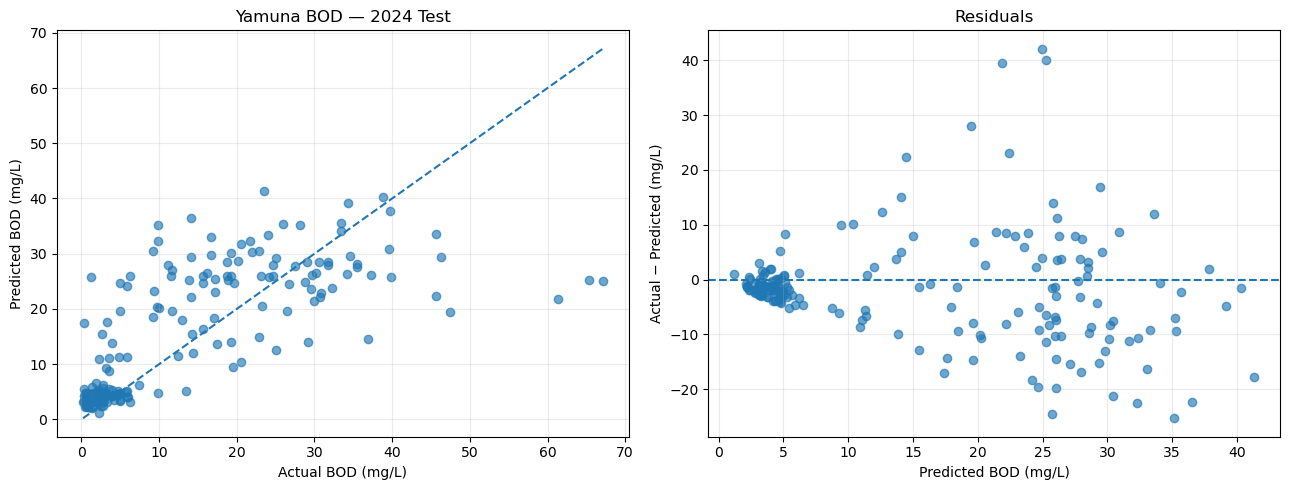

,Station,Data Acquisition Time,lag1_gap_days,Actual_BOD,Predicted_BOD,Absolute_Error
1183,ETAWAH,2024-02-21 09:10:00,9.006944,67.1,24.983432,42.116568
1320,AGRA(POIYAGHAT),2024-09-21 09:30:00,8.986111,65.3,25.236841,40.063159
1322,"Kailas Mandir, Agra",2024-09-21 13:15:00,9.989583,61.4,21.846821,39.553179
1199,AGRA(POIYAGHAT),2024-03-22 09:15:00,10.989583,47.5,19.439607,28.060393
1209,ETAWAH,2024-04-12 12:23:00,11.158333,9.8,35.110849,25.310849
1303,ETAWAH,2024-09-11 08:40:00,8.979167,1.2,25.715194,24.515194
1197,"Kailas Mandir, Agra",2024-03-21 14:00:00,9.979167,45.6,22.412025,23.187975
1201,ETAWAH,2024-04-01 08:35:00,10.961806,9.8,32.246548,22.446548
1162,ETAWAH,2024-01-11 21:20:00,10.503472,14.1,36.534279,22.434279
1324,AGRA (J.B.),2024-09-22 07:50:00,9.982639,36.9,14.471126,22.428874


In [10]:
fig, axes = plt.subplots(1,2,figsize=(13,5))
axes[0].scatter(y_test, test_pred, alpha=.65)
lo, hi = min(float(y_test.min()),float(test_pred.min())), max(float(y_test.max()),float(test_pred.max()))
axes[0].plot([lo,hi],[lo,hi],"--")
axes[0].set(xlabel="Actual BOD (mg/L)", ylabel="Predicted BOD (mg/L)", title="Yamuna BOD — 2024 Test")
axes[0].grid(alpha=.25)

resid = y_test.to_numpy()-test_pred
axes[1].scatter(test_pred,resid,alpha=.65)
axes[1].axhline(0,linestyle="--")
axes[1].set(xlabel="Predicted BOD (mg/L)",ylabel="Actual − Predicted (mg/L)",title="Residuals")
axes[1].grid(alpha=.25)
plt.tight_layout()
plt.savefig(ARTIFACT_DIR/"yamuna_bod_test_diagnostics.png",dpi=180,bbox_inches="tight")
plt.show()

errors = test[["Station","Data Acquisition Time","lag1_gap_days"]].copy()
errors["Actual_BOD"] = y_test.to_numpy()
errors["Predicted_BOD"] = test_pred
errors["Absolute_Error"] = np.abs(errors["Actual_BOD"]-errors["Predicted_BOD"])
display(errors.sort_values("Absolute_Error",ascending=False).head(20))
errors.to_csv(ARTIFACT_DIR/"yamuna_bod_test_predictions.csv",index=False)

## 10. Feature importance

,Feature,Importance
0,Biochemical Oxygen Demand (mg/L)_lag1,0.432925
1,Biochemical Oxygen Demand (mg/L)_lag2,0.216850
2,Biochemical Oxygen Demand (mg/L)_lag3,0.077130
14,Electric Conductivity (μS/cm)_lag3,0.039513
9,Total Dissolved Solids (mg/L)_lag1,0.036751
5,Dissolved oxygen (mg/L)_lag3,0.035065
8,Potential of Hydrogen (pH)_lag3,0.022633
11,Total Dissolved Solids (mg/L)_lag3,0.019875
4,Dissolved oxygen (mg/L)_lag2,0.019850
3,Dissolved oxygen (mg/L)_lag1,0.014103


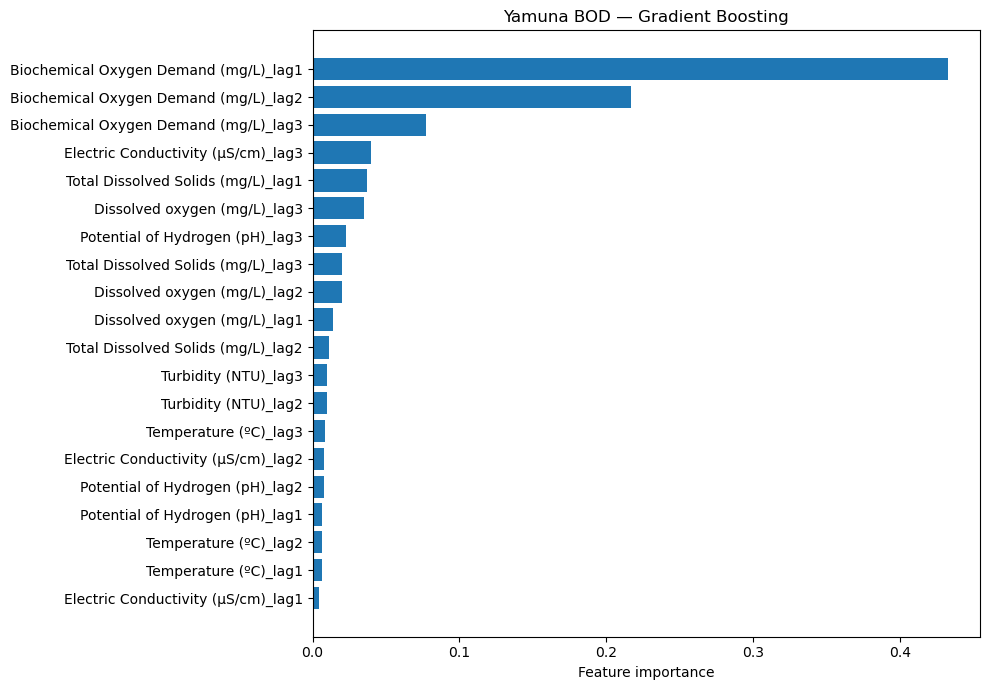

In [11]:
feature_names = model.named_steps["preprocessor"].get_feature_names_out()
importance = model.named_steps["regressor"].feature_importances_
importance_df = pd.DataFrame({"Feature":feature_names,"Importance":importance}).sort_values("Importance",ascending=False)
display(importance_df.head(25))
importance_df.to_csv(ARTIFACT_DIR/"yamuna_bod_feature_importance.csv",index=False)
top = importance_df.head(20).sort_values("Importance")
plt.figure(figsize=(10,7))
plt.barh(top["Feature"],top["Importance"])
plt.xlabel("Feature importance")
plt.title("Yamuna BOD — Gradient Boosting")
plt.tight_layout()
plt.savefig(ARTIFACT_DIR/"yamuna_bod_feature_importance.png",dpi=180,bbox_inches="tight")
plt.show()

## 11. Export model, metadata, smoke test, and ZIP

In [12]:

model_path = ARTIFACT_DIR / "yamuna_bod_gbr_pipeline.joblib"
joblib.dump(model, model_path)

metadata = {
    "project": "AQUA",
    "river": "Yamuna",
    "target": target_col,
    "target_units": "mg/L",
    "model": "GradientBoostingRegressor pipeline",
    "parameters": {
        "n_estimators": 200,
        "learning_rate": 0.03,
        "max_depth": 3,
        "min_samples_leaf": 3,
        "subsample": 1.0,
        "random_state": RANDOM_STATE
    },
    "resolved_water_quality_columns": resolved,
    "lag_features": lag_features,
    "train_years": TRAIN_YEARS,
    "validation_year": VALIDATION_YEAR,
    "test_year": TEST_YEAR,
    "gap_filter_days": (
        [MIN_GAP_DAYS, MAX_GAP_DAYS]
        if FILTER_TO_7_14_DAY_GAP else None
    ),
    "stations": sorted(data["Station"].astype(str).unique().tolist()),
    "metrics": metrics_df.to_dict(orient="records"),
    "note": "Fresh metrics from this run. Model explanations are not causal."
}

with open(
    ARTIFACT_DIR / "yamuna_bod_model_metadata.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(metadata, f, indent=2, ensure_ascii=False)

# Verify that the saved model loads and reproduces predictions
reloaded = joblib.load(model_path)
n = min(10, len(X_test))

assert np.allclose(
    model.predict(X_test.iloc[:n]),
    reloaded.predict(X_test.iloc[:n])
)

print("Export smoke test passed.")

# Create the ZIP on your Windows computer
zip_path = DATA_DIR / "AQUA_Yamuna_Model_Artifacts.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for p in ARTIFACT_DIR.iterdir():
        if p.is_file():
            z.write(p, arcname=p.name)

print("Model:", model_path)
print("Metadata:", ARTIFACT_DIR / "yamuna_bod_model_metadata.json")
print("Artifact ZIP:", zip_path)
print("Files:", [p.name for p in ARTIFACT_DIR.iterdir() if p.is_file()])


Export smoke test passed.
Model: C:\Users\ashma\OneDrive\Documents\AQUA_Data\artifacts\yamuna_bod_gbr_pipeline.joblib
Metadata: C:\Users\ashma\OneDrive\Documents\AQUA_Data\artifacts\yamuna_bod_model_metadata.json
Artifact ZIP: C:\Users\ashma\OneDrive\Documents\AQUA_Data\AQUA_Yamuna_Model_Artifacts.zip
Files: ['bod_extreme_observations_review.csv', 'yamuna_bod_feature_importance.csv', 'yamuna_bod_feature_importance.png', 'yamuna_bod_gbr_pipeline.joblib', 'yamuna_bod_metrics.csv', 'yamuna_bod_model_metadata.json', 'yamuna_bod_test_diagnostics.png', 'yamuna_bod_test_predictions.csv', 'yamuna_station_eligibility_audit.csv']


## Before integrating into the dashboard
1. Verify the selected stations are the intended Yamuna main-channel stations.
2. Compare the freshly computed metrics against the historical report; investigate differences rather than forcing a match.
3. Download `AQUA_Yamuna_Model_Artifacts.zip` from Colab's `/content` file browser.
4. This notebook trains the Yamuna BOD model only. Keep it separate from the Ganga BOD/DO/pH models in the backend.